# Step 1：单个静态人群的部署

理论解释、一次可复现实验、轨迹复判，以及这次运行能够支持的结论。

Step 1 固定为：一个静态人群、已知封闭场地、全局观测、无限通信、没有 crowd–guide 动力学交互。控制器只看见人员位置、半径和 demand 权重，看不见生成多边形。demand 是规划权重，不是已经验证的风险。边界目前是人员圆盘的凸包，凹陷不会被重建出来。

更完整的符号和限制见 `docs/STEP1_THEORY.zh.md`。本笔记不重新实现规划、导航或安全过滤。

## 实验演示

50 人案例使用固定 5×10 网格和 8 个 Guide。人员在初始化后冻结。下面若已有结果就直接读取，否则调用包内入口重跑。

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from udc.experiments.runner import experiment, reevaluate_result

ROOT = Path.cwd() if (Path.cwd() / 'configs' / 'step1' / 'static_50.yaml').exists() else Path.cwd().parent
OUTPUT = ROOT / 'runs' / 'static50'
CONFIG = ROOT / 'configs' / 'step1' / 'static_50.yaml'
if not (OUTPUT / 'metrics.json').exists():
    experiment(CONFIG, OUTPUT, plots=False)
metrics = json.loads((OUTPUT / 'metrics.json').read_text(encoding='utf-8'))
checked = reevaluate_result(OUTPUT)
print(metrics['termination_status'], 'online', metrics['success'], 'reevaluated', checked['success'])
print('active guides', metrics['active_guides'], 'simulation time [s]', metrics['simulation_time'])

SUCCESS online True reevaluated True
active guides 8 simulation time [s] 23.0


## 数据分析

验收从保存的轨迹重新计算。图中的曲线和人员位置也来自这份轨迹，而不是控制器内存。

{
  "success": true,
  "reevaluation_consistent": true,
  "simulation_time_s": 23.0,
  "actual_max_gap_m": 3.741146283388993,
  "mean_curve_distance_m": 0.0017144826012010991,
  "path_length_m": 134.33301673115835,
  "resource_utilization": 1.0,
  "minimum_net_clearances_m": {
    "crowd": 0.20009252274673073,
    "guides": 1.7433876535071713,
    "walls": 0.75
  },
  "failure_reason": "",
  "crowd_ids": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,
    16,
    17,
    18,
    19,
    20,
    21,
    22,
    23,
    24,
    25,
    26,
    27,
    28,
    29,
    30,
    31,
    32,
    33,
    34,
    35,
    36,
    37,
    38,
    39,
    40,
    41,
    42,
    43,
    44,
    45,
    46,
    47,
    48,
    49
  ],
  "crowd_speed_max": 0.0
}


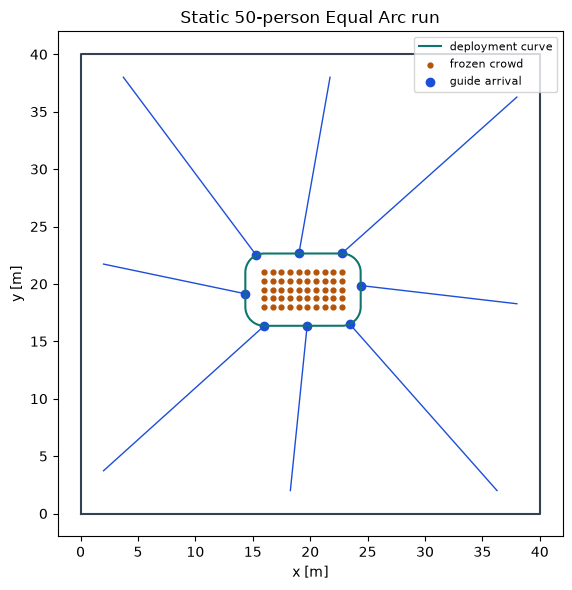

In [2]:
trace = np.load(OUTPUT / 'trajectory.npz', allow_pickle=False)
consistent = metrics['success'] == checked['success'] and metrics['criteria'] == checked['criteria']
summary = {
    'success': metrics['success'],
    'reevaluation_consistent': consistent,
    'simulation_time_s': metrics['simulation_time'],
    'actual_max_gap_m': metrics['actual_max_gap'],
    'mean_curve_distance_m': metrics['mean_curve_distance'],
    'path_length_m': metrics['path_length'],
    'resource_utilization': metrics['resource_utilization'],
    'minimum_net_clearances_m': metrics['minimum_net_clearances'],
    'failure_reason': metrics['failure_reason'],
    'crowd_ids': trace['crowd_ids'].tolist(),
    'crowd_speed_max': float(np.linalg.norm(trace['crowd_velocities'], axis=1).max()),
}
print(json.dumps(summary, indent=2, ensure_ascii=False))

positions = trace['positions']
room = trace['room']
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, room[0], room[0], 0, 0], [0, 0, room[1], room[1], 0], color='#334155')
deployment = trace['boundary_deployment']
ax.plot(*np.vstack([deployment, deployment[0]]).T, color='#0f766e', label='deployment curve')
ax.scatter(trace['crowd_positions'][:, 0], trace['crowd_positions'][:, 1], s=12, c='#b45309', label='frozen crowd')
for guide in range(positions.shape[1]):
    ax.plot(positions[:, guide, 0], positions[:, guide, 1], color='#1d4ed8', lw=1)
ax.scatter(positions[-1, :, 0], positions[-1, :, 1], c='#1d4ed8', label='guide arrival')
ax.set_aspect('equal')
ax.set_xlabel('x [m]')
ax.set_ylabel('y [m]')
ax.set_title('Static 50-person Equal Arc run')
ax.legend(loc='upper right', fontsize=8)
fig.tight_layout()
plt.show()

## 结论

下面这段只描述上一个单元打印出来的这一次确定性运行。网格重复不能当成独立随机样本，也不能外推到其他形状、规模或部署方法。20／24 Guide 的高需求诊断和四算法因子表是单独的实验，不由这一次 8 Guide 成功来代表。

In [3]:
if not summary['reevaluation_consistent']:
    raise RuntimeError('独立复判与在线验收不一致')
if summary['crowd_speed_max'] != 0:
    raise RuntimeError('Step 1 人群速度应为 0')
print(
    f"这次 50 人网格、Equal Arc、8 个 Guide 的运行结果是 {metrics['termination_status']}。"
    f"仿真时间 {summary['simulation_time_s']} s，实际最大间隙 {summary['actual_max_gap_m']:.3f} m，"
    f"平均曲线距离 {summary['mean_curve_distance_m']:.4f} m，规划路径总长 {summary['path_length_m']:.2f} m，"
    f"资源利用率 {summary['resource_utilization']:.2f}。"
    f"最小净裕量：人 {summary['minimum_net_clearances_m']['crowd']:.3f} m，"
    f"Guide {summary['minimum_net_clearances_m']['guides']:.3f} m，"
    f"墙 {summary['minimum_net_clearances_m']['walls']:.3f} m。"
    '在线验收与轨迹复判一致，人群保持静止。这不能说明其他部署方法或资源水平具有同样结果。'
)

这次 50 人网格、Equal Arc、8 个 Guide 的运行结果是 SUCCESS。仿真时间 23.0 s，实际最大间隙 3.741 m，平均曲线距离 0.0017 m，规划路径总长 134.33 m，资源利用率 1.00。最小净裕量：人 0.200 m，Guide 1.743 m，墙 0.750 m。在线验收与轨迹复判一致，人群保持静止。这不能说明其他部署方法或资源水平具有同样结果。
